# Lab3b — Counterfactual Explanations with DiCE

This lab covers **counterfactual explanations** for a black-box classifier using **DiCE (Diverse Counterfactual Explanations)** on the Adult Income dataset.

| Concept | Description |
|---|---|
| **Counterfactual** | A minimally changed input that leads the model to a desired alternative prediction |
| **Actionability** | Restricting which features are allowed to change |
| **Feasibility** | Restricting changed values to admissible ranges or categories |
| **Diversity** | Returning multiple distinct counterfactual alternatives |
| **Local CF importance** | Fraction of generated counterfactuals in which each feature changes |

**Guide:**
- ⚙️ Data preparation and black-box model
- 🔄 Basic counterfactual generation
- 🎯 Actionability constraints
- ✅ Feasibility constraints
- 📊 Counterfactual-based local feature importance

We use the model-agnostic **random-sampling** method implemented in `dice-ml`.


## 🔍 What is a counterfactual explanation?

Given an instance $x$ with prediction $f(x)$, a counterfactual explanation searches for another instance $x'$ such that

$$f(x') = y', \qquad y' \neq f(x)$$

while keeping $x'$ reasonably close to $x$ and respecting domain constraints.

A counterfactual therefore answers a question of the form:

> **What would have to change in this instance for the model to produce a different outcome?**

A useful counterfactual should normally satisfy several properties:

1. **Validity:** it reaches the desired model outcome.
2. **Proximity:** it does not change the original instance unnecessarily.
3. **Actionability:** it changes features that can meaningfully be modified.
4. **Feasibility:** the resulting values remain plausible or admissible.
5. **Diversity:** when several counterfactuals are returned, they should provide different alternatives.

> ⚠️ Counterfactual explanations describe the behaviour of the **predictive model**. They do not establish that changing a feature will causally change the real-world outcome.

Reference: Mothilal, Sharma, and Tan, *Explaining Machine Learning Classifiers through Diverse Counterfactual Explanations* (FAccT 2020).


## ⚙️ Data Preparation (~10 min)

We use the **Adult Income** dataset from the UCI Machine Learning Repository. Each row describes an individual, and the target is whether annual income is above $50K.

The workflow follows the same discipline as the previous labs:

- split the data before fitting preprocessing transformations;
- fit preprocessing and the classifier on the training set only;
- keep the test set for evaluation and explanations.


### ⚙️ Step 1 — Install & Imports


In [1]:
%pip install -q ucimlrepo dice-ml

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import dice_ml



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### ⚙️ Step 2 — Load the Adult Dataset

We load the dataset from UCI and encode the outcome as

$$0 = \text{income} \leq 50K, \qquad 1 = \text{income} > 50K$$

Using a numeric target keeps the classifier and DiCE interface simple and makes the desired opposite class unambiguous.


In [2]:
adult = fetch_ucirepo(id=2)

X = adult.data.features.copy()
y = adult.data.targets.iloc[:, 0].copy()
y = y.replace({'<=50K': 0, '>50K': 1, '<=50K.': 0, '>50K.': 1}).astype(int)

target_class = y.name if y.name is not None else 'income'
attributes = X.columns.tolist()

print('X shape:', X.shape)
print('Target distribution:')
print(y.value_counts(normalize=True).sort_index())


X shape: (48842, 14)
Target distribution:
income
0    0.760718
1    0.239282
Name: proportion, dtype: float64


/var/folders/_g/_pf7z99n3d5b6dc69k3t8rj40000gn/T/ipykernel_16042/119615310.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y = y.replace({'<=50K': 0, '>50K': 1, '<=50K.': 0, '>50K.': 1}).astype(int)


### ⚙️ Step 3 — Stratified Train / Test Split

Use an **80/20** split and stratify by the target so that both sets preserve approximately the same class proportions.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Train:', X_train.shape, ' Test:', X_test.shape)


Train: (39073, 14)  Test: (9769, 14)


### ⚙️ Step 4 — Preprocess and Train the Black-Box Classifier

Categorical variables are One-Hot Encoded and numerical variables are standardized inside a `Pipeline`. Keeping preprocessing inside the pipeline is important because DiCE will generate counterfactuals in the **original feature space**, while the classifier still receives exactly the representation used during training.


In [5]:
numerical = [
    'age', 'fnlwgt', 'hours-per-week',
    'education-num', 'capital-gain', 'capital-loss' #on sépare les colonnes numériques des catégorielles
]
categorical = X_train.columns.difference(numerical).tolist()

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler()) #scaler pour les colonnes numériques pour standardiser les données
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore')) #OneHotEncoder pour transformer les variables catégorielles (ex:Bachelor=0, Master=1, PhD=0)
])

preprocessor = ColumnTransformer(
    transformers=[ #on rassemble les 2 transformateurs précédents (gère numériques et catégorielles)
        ('num', numeric_transformer, numerical),
        ('cat', categorical_transformer, categorical)
    ]
)

clf = Pipeline(steps=[ #Pipeline permet d'enchainer plusieurs étapes de traitement dans un seul objet : ici préprocessing et RandomForest
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

clf.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital-loss','hours-per-week', 'native-country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

### ⚙️ Step 5 — Evaluate the Classifier


In [6]:
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Test accuracy: {accuracy:.3f}')


Test accuracy: 0.856


### ⚙️ Step 6 — Build the DiCE Data, Model, and Explainer Objects

DiCE needs:

1. a `Data` object describing the original feature space;
2. a `Model` wrapper around the trained predictor;
3. a `Dice` explainer specifying the counterfactual-generation method.

We use `method="random"`, which generates candidates through model-agnostic randomized sampling.


In [7]:
#### START CODE HERE (~10 lines) ####
# TODO:
# 1. Create df_data from X_train and append the target column.
# 2. Build dice_ml.Data using numerical as continuous_features.
# 3. Wrap clf with dice_ml.Model(..., backend='sklearn').
# 4. Create dice_ml.Dice(..., method='random').
df_data = X_train.copy()
df_data[target_class] = y_train

d = dice_ml.Data(
    dataframe=df_data, #dataframe utilisé
    continuous_features=numerical, #listes des variables numériques
    outcome_name=target_class #nom de la colonne cible
)

m = dice_ml.Model(model=clf,backend='sklearn') #modèle entrainé (ici clf plus haut) et la technologie utilisée pour créer le modèle (ici sklearn)
dice_alg = dice_ml.Dice(d, m, method='random') #(data,model dice,méthode de génération par échantillonnage aléatoire)

#### END CODE HERE ####


> ✅ **Setup complete.** DiCE now works in the original semantic feature space, while the sklearn pipeline transparently performs the encoding required by the Random Forest.


## Exercise 1 — Generate Counterfactuals for One Instance 🔄

We start with one observation from the test set and ask DiCE to generate alternative profiles that receive the **opposite predicted class**.

**Your tasks:**
1. Select the first test instance.
2. Inspect the model's original prediction and class probabilities.
3. Generate three counterfactuals.
4. Verify that the generated instances receive the desired prediction.


### 1.1 — Select and Predict the Query Instance


In [19]:
#### START CODE HERE (~7 lines) ####
# TODO:
# 1. Select the first test instance as a one-row DataFrame.
# 2. Compute its predicted class and predict_proba output.
# 3. Print the class and a class->probability dictionary.
# 4. Display query_instance.

query_instance = X_test.iloc[[0]].copy()
print(query_instance)
#il faut utiliser iloc[[0]] et non iloc[0] car on veut un DataFrame en 1 ligne (iloc[0] = retourne une Series)

original_prediction = clf.predict(query_instance)[0]
original_probabilities = clf.predict_proba(query_instance)[0]

print("Original Predicition",original_prediction)
print("Original Probabilities",dict(zip(clf.classes_,original_probabilities)))
query_instance

#### END CODE HERE ####


       age workclass  fnlwgt education  education-num marital-status  \
40421   30   Private  378009   HS-grad              9  Never-married   

              occupation relationship   race   sex  capital-gain  \
40421  Machine-op-inspct    Own-child  White  Male             0   

       capital-loss  hours-per-week native-country  
40421             0              40  United-States  
Original Predicition 0
Original Probabilities {np.int64(0): np.float64(1.0), np.int64(1): np.float64(0.0)}


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
40421,30,Private,378009,HS-grad,9,Never-married,Machine-op-inspct,Own-child,White,Male,0,0,40,United-States


### 1.2 — Generate Three Counterfactuals

`desired_class="opposite"` asks DiCE to search for instances whose prediction is the opposite class. `random_seed` makes the randomized search reproducible.


In [ ]:
#### START CODE HERE (~7 lines) ####
# TODO: generate 3 counterfactuals for query_instance using
# desired_class='opposite', verbose=False, and random_seed=7.
dice_exp = dice_alg.generate_counterfactuals(
    query_instance,
    total_CFs=3, #nombre de counterfactuals voulus
    desired_class='opposite',
    verbose=True,
    random_seed=42
)

#### END CODE HERE ####


100%|██████████| 1/1 [00:00<00:00,  2.65it/s]

Diverse Counterfactuals found! total time taken: 00 min 00 sec


### 1.3 — Inspect and Verify the Counterfactuals

With `show_only_changes=True`, unchanged values are suppressed so that the explanation emphasizes the modifications relative to the query instance.


In [ ]:
dice_exp.visualize_as_dataframe(show_only_changes=True) #on dit de n'afficher que les caractéristiques qui ont changés

Query instance (original outcome : 0)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,30,Private,378009,HS-grad,9,Never-married,Machine-op-inspct,Own-child,White,Male,0,0,40,United-States,0



Diverse Counterfactual set (new outcome: 1)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,-,-,-,-,-,-,-,-,-,-,92093,-,-,-,1
1,-,-,-,-,-,-,-,-,-,-,12161,-,-,-,1
2,-,-,-,-,-,-,-,-,-,-,48136,-,-,-,1


In [ ]:
#### START CODE HERE (~6 lines) ####
# TODO:
# 1. Extract final_cfs_df from the first CounterfactualExamples object.
# 2. Predict the generated counterfactuals using the original attributes.
# 3. Check whether all predictions differ from original_prediction.
# 4. Display the counterfactual DataFrame.
counterfactuals_df = dice_exp.cf_examples_list[0].final_cfs_df.copy()
cf_predictions = clf.predict(counterfactuals_df[attributes]) #prédire les classes des counterfals

print('Counterfactual predictions:', cf_predictions)
print('All predictions changed:', np.all(cf_predictions != original_prediction)) #vérifie si toutes les prédictions ont bien changées --> Valide
counterfactuals_df


#### END CODE HERE ####


Counterfactual predictions: [1 1 1]
All predictions changed: True


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,30,Private,378009,HS-grad,9,Never-married,Machine-op-inspct,Own-child,White,Male,92093,0,40,United-States,1
1,30,Private,378009,HS-grad,9,Never-married,Machine-op-inspct,Own-child,White,Male,12161,0,40,United-States,1
2,30,Private,378009,HS-grad,9,Never-married,Machine-op-inspct,Own-child,White,Male,48136,0,40,United-States,1


## Exercise 2 — Actionable Counterfactuals 🎯

A counterfactual can be valid for the model but still be useless as recourse if it changes variables that the decision subject cannot reasonably modify.

DiCE uses `features_to_vary` to specify which attributes may change. All other features remain fixed.

In this example we allow changes only to an illustrative set of potentially modifiable attributes. Whether a variable is truly actionable always depends on the application and time horizon.


In [25]:
#### START CODE HERE (~13 lines) ####
# TODO:
# 1. Define the illustrative actionable feature set used in the solution.
# 2. Generate 3 counterfactuals with desired_class='opposite',
#    features_to_vary=actionable_features, and random_seed=7.
# 3. Visualize only the changed values.
actionable_features = [
    'workclass', 'education', 'occupation',
    'hours-per-week', 'capital-gain', 'capital-loss'
]


dice_actionable = dice_alg.generate_counterfactuals(
    query_instance,
    total_CFs=3,
    desired_class='opposite',
    features_to_vary=actionable_features, #définit les features à faire varier qui sont ok
    random_seed=7
)

dice_actionable.visualize_as_dataframe(show_only_changes=True)

#### END CODE HERE ####


100%|██████████| 1/1 [00:00<00:00,  2.70it/s]

Query instance (original outcome : 0)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,30,Private,378009,HS-grad,9,Never-married,Machine-op-inspct,Own-child,White,Male,0,0,40,United-States,0



Diverse Counterfactual set (new outcome: 1)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,-,-,-,-,-,-,-,-,-,-,44230,1211,-,-,1
1,-,-,-,-,-,-,-,-,-,-,33001,-,93,-,1
2,-,-,-,-,-,-,-,-,-,-,54360,2262,-,-,1


## Exercise 3 — Feasible Counterfactuals ✅

Actionability specifies **which features may change**. Feasibility additionally constrains **which values are allowed**.

DiCE uses `permitted_range` to restrict admissible values. For example, we may require age and weekly working hours to stay within a specified range.

> 💡 A permitted range is a domain constraint, not evidence that every point inside that range is realistic. More sophisticated feasibility constraints may require causal, temporal, or structural knowledge.


In [26]:
#### START CODE HERE (~12 lines) ####
# TODO:
# 1. Define permitted ranges for age=[22, 50] and hours-per-week=[20, 60].
# 2. Generate 5 opposite-class counterfactuals using this permitted_range.
# 3. Use random_seed=7.
# 4. Visualize only the changed values.
permitted_range = {
    'age': [22, 50],
    'hours-per-week': [20, 60]
}

dice_feasible = dice_alg.generate_counterfactuals(
    query_instance,
    total_CFs=5,
    desired_class='opposite',
    permitted_range=permitted_range, #définit les plages autorisées dans les changements
    random_seed=7
)

dice_feasible.visualize_as_dataframe(show_only_changes=True)

#### END CODE HERE ####


100%|██████████| 1/1 [00:00<00:00,  1.94it/s]

Query instance (original outcome : 0)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,30,Private,378009,HS-grad,9,Never-married,Machine-op-inspct,Own-child,White,Male,0,0,40,United-States,0



Diverse Counterfactual set (new outcome: 1)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,49,-,-,-,-,-,-,-,-,-,48581,-,-,-,1
1,-,-,-,10th,-,-,-,-,-,-,27285,-,-,-,1
2,-,-,-,-,-,-,-,-,-,-,48128,-,-,-,1
3,-,-,-,-,-,-,-,-,-,-,42387,-,-,-,1
4,-,-,-,-,-,-,-,-,-,-,70528,-,-,-,1


## Exercise 4 — Local Feature Importance from Counterfactuals 📊

DiCE can summarize a set of counterfactuals through **counterfactual-based local feature importance**.

For one query instance, the importance of a feature is the **fraction of generated counterfactuals in which that feature changes** relative to the original instance. Therefore:

$$
\text{importance}_j
=
\frac{\#\{\text{counterfactuals where feature } j \text{ changes}\}}
{\#\{\text{generated counterfactuals}\}}.
$$

A larger value means that the feature is changed more frequently among the generated alternatives. This is **not** the same as global predictive feature importance and should not be interpreted causally.

DiCE requires at least **10 counterfactuals per query instance** when computing this quantity.


In [ ]:
#### START CODE HERE (~15 lines) ####
# TODO:
# 1. Generate 20 opposite-class counterfactuals for query_instance.
# 2. Compute dice_alg.local_feature_importance using those precomputed CFs.
# 3. Convert the first local_importance dictionary to a pandas Series.
# 4. Sort the Series in descending order and display it.
dice_for_importance = dice_alg.generate_counterfactuals(
    query_instance,
    total_CFs=20,
    desired_class='opposite',
    verbose=False,
    random_seed=7
)

importance_exp = dice_alg.local_feature_importance(
    query_instance, ##objectif est de mesurer la fréquence à laquelle chaque caractéristique change parmi les counterfactuals générées.
    cf_examples_list=dice_for_importance.cf_examples_list
)

local_importance = pd.Series(importance_exp.local_importance[0]).sort_values(ascending=False) #conversion en panda series
local_importance


#### END CODE HERE ####


100%|██████████| 1/1 [00:01<00:00,  1.36s/it]


capital-gain      1.00
capital-loss      0.15
workclass         0.05
education         0.05
marital-status    0.05
race              0.05
sex               0.05
native-country    0.05
age               0.05
hours-per-week    0.05
occupation        0.00
relationship      0.00
fnlwgt            0.00
education-num     0.00
dtype: float64

### 4.1 — Plot the Local Counterfactual Feature Importance


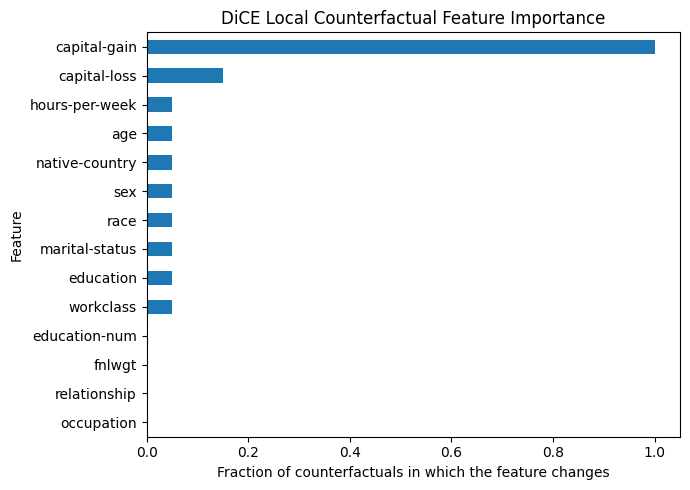

In [ ]:
#### START CODE HERE (~7 lines) ####
# TODO: create a horizontal bar chart of local_importance.
# Label the x-axis as the fraction of counterfactuals in which the feature changes.
# Add a y-label, title, tight_layout(), and show the plot.
local_importance.sort_values().plot.barh(figsize=(7, 5))
plt.xlabel('Fraction of counterfactuals in which the feature changes')
plt.ylabel('Feature')
plt.title('DiCE Local Counterfactual Feature Importance')
plt.tight_layout()
plt.show()
#### END CODE HERE ####


### 🔍 Reflection Questions

1. **Validity vs usefulness:** If a generated counterfactual flips the model prediction, is it automatically a useful recommendation? Why or why not?

2. **Actionability vs feasibility:** What is the difference between `features_to_vary` and `permitted_range`? Give one example where both constraints would be needed.

3. **Multiplicity and diversity:** Why can multiple valid counterfactuals exist for the same instance? Why might showing several alternatives be preferable to showing only one?

4. **Randomness and stability:** The `random` DiCE method uses randomized sampling. What might change if you use a different `random_seed`? What would you check before presenting a counterfactual explanation to a user?

5. **Counterfactual feature importance:** What does a value of `0.8` mean for one feature in `local_feature_importance`? Why should it not be interpreted as “the feature explains 80% of the prediction”?

6. **Causality:** If a counterfactual says that changing a feature would flip the model prediction, does that imply that changing the feature in the real world would cause the desired real-world outcome?


### ✅ Suggested Answers to the Reflection Questions

1. **Validity vs usefulness.** No. Validity only means that the model output changes as requested. A useful counterfactual should also be sufficiently close to the original instance, actionable for the user, feasible in the domain, and preferably robust to small perturbations or model uncertainty.

2. **Actionability vs feasibility.** `features_to_vary` controls **which variables are allowed to change**. `permitted_range` controls **which values those variables may take**. For example, `hours-per-week` may be allowed to change, while a permitted range such as 20--60 prevents unrealistic values.

3. **Multiplicity and diversity.** Many different feature combinations may cross the model's decision boundary. Showing several diverse alternatives gives the user choices and reveals that the model may admit different routes to the same desired prediction.

4. **Randomness and stability.** A different seed can produce different candidate counterfactuals because randomized sampling explores a different set of points. Before presenting an explanation, check whether valid alternatives can be found consistently and whether their main changes remain qualitatively stable across seeds or generation methods.

5. **Counterfactual feature importance.** A value of `0.8` means that the feature changed in 80% of the counterfactuals used for that local summary. It measures how frequently the generation procedure relied on that feature for this query; it is not a decomposition of the original prediction and does not sum to 1 across features.

6. **Causality.** No. Counterfactual explanations are counterfactuals of the **model**, not automatically of the real data-generating process. Without a causal model, the explanation does not establish that intervening on the feature would cause the real-world outcome to change.


## ⭐ Optional Extension — Compare Counterfactual Generation Methods

DiCE also supports other model-agnostic generation strategies, including a **genetic algorithm** and **KD-tree-based** counterfactuals. Compare them with the random method in terms of:

- runtime;
- proximity to the query instance;
- diversity of the returned alternatives;
- sensitivity to random initialization;
- whether the counterfactuals correspond to observed training instances.
